In [217]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import silhouette_score

In [218]:
%pip install openpyxl

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip available: 22.3.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [219]:
import pandas as pd

df = pd.read_excel("Online Retail.xlsx")

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)

df.head()

Dataset loaded successfully!
Dataset shape: (541909, 8)


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom


In [220]:
print("Column Names:")
print(df.columns.tolist())

print("\nFirst 5 Records:")
display(df.head())

print("\nDataset Information:")
df.info()

Column Names:
['InvoiceNo', 'StockCode', 'Description', 'Quantity', 'InvoiceDate', 'UnitPrice', 'CustomerID', 'Country']

First 5 Records:


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom



Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 541909 entries, 0 to 541908
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype         
---  ------       --------------   -----         
 0   InvoiceNo    541909 non-null  object        
 1   StockCode    541909 non-null  object        
 2   Description  540455 non-null  object        
 3   Quantity     541909 non-null  int64         
 4   InvoiceDate  541909 non-null  datetime64[ns]
 5   UnitPrice    541909 non-null  float64       
 6   CustomerID   406829 non-null  float64       
 7   Country      541909 non-null  object        
dtypes: datetime64[ns](1), float64(2), int64(1), object(4)
memory usage: 33.1+ MB


In [221]:
# 1. Check missing values
print("Missing values:")
print(df.isnull().sum())

# 2. Check duplicate rows
print("\nDuplicate rows:", df.duplicated().sum())

# 3. Check cancelled invoices
print("\nCancelled invoices:", df["InvoiceNo"].astype(str).str.startswith("C").sum())

# 4. Check quantity and price
print("\nQuantity summary:")
print(df["Quantity"].describe())

print("\nUnit price summary:")
print(df["UnitPrice"].describe())

Missing values:
InvoiceNo           0
StockCode           0
Description      1454
Quantity            0
InvoiceDate         0
UnitPrice           0
CustomerID     135080
Country             0
dtype: int64

Duplicate rows: 5268

Cancelled invoices: 9288

Quantity summary:
count    541909.000000
mean          9.552250
std         218.081158
min      -80995.000000
25%           1.000000
50%           3.000000
75%          10.000000
max       80995.000000
Name: Quantity, dtype: float64

Unit price summary:
count    541909.000000
mean          4.611114
std          96.759853
min      -11062.060000
25%           1.250000
50%           2.080000
75%           4.130000
max       38970.000000
Name: UnitPrice, dtype: float64


In [222]:
# Make a copy so the original dataset remains unchanged
df_clean = df.copy()

# Remove exact duplicate records
df_clean = df_clean.drop_duplicates()

# Remove transactions without a CustomerID
df_clean = df_clean.dropna(subset=["CustomerID"])

# Remove cancelled invoices
df_clean = df_clean[
    ~df_clean["InvoiceNo"].astype(str).str.startswith("C")
]

# Keep transactions with positive quantity and unit price
df_clean = df_clean[
    (df_clean["Quantity"] > 0) &
    (df_clean["UnitPrice"] > 0)
]

# Calculate total sales value for each transaction line
df_clean["TotalAmount"] = (
    df_clean["Quantity"] * df_clean["UnitPrice"]
)

print("Original rows:", len(df))
print("Cleaned rows:", len(df_clean))
print("Remaining missing CustomerIDs:",
      df_clean["CustomerID"].isnull().sum())
print("Remaining duplicate rows:",
      df_clean.duplicated().sum())

df_clean.head()

Original rows: 541909
Cleaned rows: 392692
Remaining missing CustomerIDs: 0
Remaining duplicate rows: 0


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,TotalAmount
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom,15.30
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,20.34
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom,22.00
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,20.34
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,20.34


In [223]:
customer_data = df_clean.groupby("CustomerID").agg(
    Total_Spending=("TotalAmount", "sum"),
    Total_Orders=("InvoiceNo", "nunique"),
    Total_Quantity=("Quantity", "sum")
).reset_index()

print("Customer dataset shape:", customer_data.shape)

customer_data.head()

Customer dataset shape: (4338, 4)


,CustomerID,Total_Spending,Total_Orders,Total_Quantity
0,12346.0,77183.60,1,74215
1,12347.0,4310.00,7,2458
2,12348.0,1797.24,4,2341
3,12349.0,1757.55,1,631
4,12350.0,334.40,1,197


In [224]:
print("Customer dataset information:")
customer_data.info()

print("\nStatistical summary:")
display(customer_data[
    ["Total_Spending", "Total_Orders", "Total_Quantity"]
].describe())

print("\nMissing values:")
print(customer_data.isnull().sum())

Customer dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4338 entries, 0 to 4337
Data columns (total 4 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   CustomerID      4338 non-null   float64
 1   Total_Spending  4338 non-null   float64
 2   Total_Orders    4338 non-null   int64  
 3   Total_Quantity  4338 non-null   int64  
dtypes: float64(2), int64(2)
memory usage: 135.7 KB

Statistical summary:


,Total_Spending,Total_Orders,Total_Quantity
count,4338.000000,4338.000000,4338.000000
mean,2048.688081,4.272015,1187.644537
std,8985.230220,7.697998,5043.619654
min,3.750000,1.000000,1.000000
25%,306.482500,1.000000,159.000000
50%,668.570000,2.000000,378.000000
75%,1660.597500,5.000000,989.750000
max,280206.020000,209.000000,196915.000000



Missing values:
CustomerID        0
Total_Spending    0
Total_Orders      0
Total_Quantity    0
dtype: int64


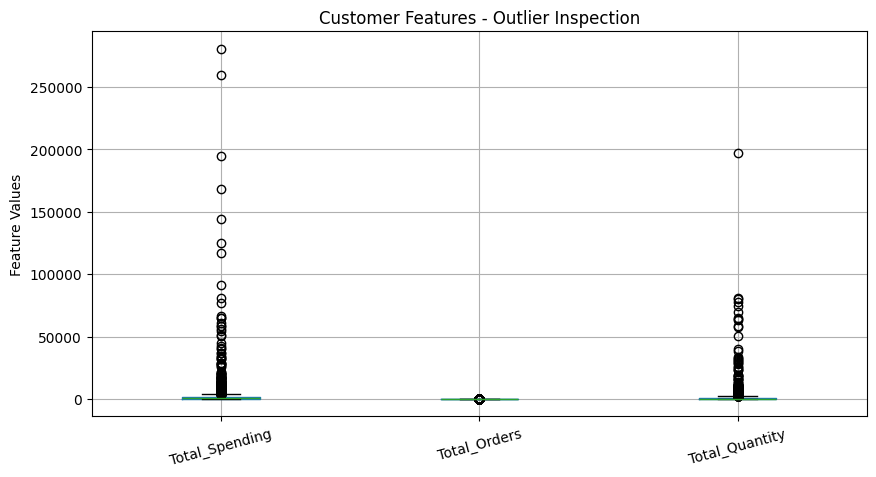

,Total_Spending,Total_Orders,Total_Quantity
count,4338.00,4338.00,4338.00
mean,2048.69,4.27,1187.64
std,8985.23,7.70,5043.62
min,3.75,1.00,1.00
25%,306.48,1.00,159.00
50%,668.57,2.00,378.00
75%,1660.60,5.00,989.75
max,280206.02,209.00,196915.00


In [225]:
features = [
    "Total_Spending",
    "Total_Orders",
    "Total_Quantity"
]

customer_data[features].boxplot(figsize=(10, 5))
plt.title("Customer Features - Outlier Inspection")
plt.ylabel("Feature Values")
plt.xticks(rotation=15)
plt.show()

display(customer_data[features].describe().round(2))

,Total_Spending,Total_Orders,Total_Quantity
0,11.253955,0.693147,11.214735
1,8.368925,2.079442,7.807510
2,7.494564,1.609438,7.758761
3,7.472245,0.693147,6.448889
4,5.815324,0.693147,5.288267


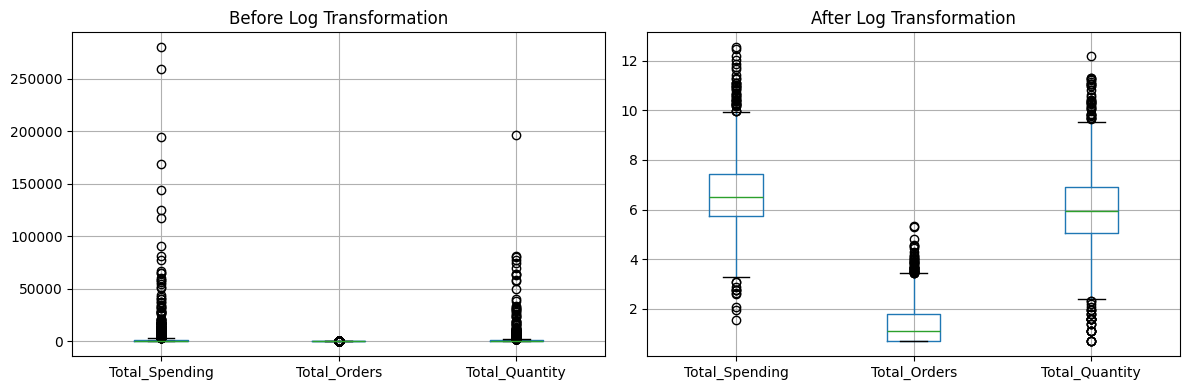

In [226]:
# Select features for clustering
features = [
    "Total_Spending",
    "Total_Orders",
    "Total_Quantity"
]

# Apply log transformation
X_log = np.log1p(customer_data[features])

# Inspect the transformed features
display(X_log.head())

# Compare distributions before and after transformation
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

customer_data[features].boxplot(ax=axes[0])
axes[0].set_title("Before Log Transformation")

X_log.boxplot(ax=axes[1])
axes[1].set_title("After Log Transformation")

plt.tight_layout()
plt.show()

In [227]:
# Create the scaler
scaler = StandardScaler()

# Standardize the transformed features
X_scaled = scaler.fit_transform(X_log)

print("Scaled data shape:", X_scaled.shape)

print("\nFirst 5 scaled rows:")
print(X_scaled[:5])

Scaled data shape: (4338, 3)

First 5 scaled rows:
[[ 3.7077163  -0.95521426  3.8189491 ]
 [ 1.41490344  1.07442519  1.33269016]
 [ 0.72002428  0.38630445  1.29711755]
 [ 0.70228691 -0.95521426  0.34130193]
 [-0.61451388 -0.95521426 -0.50560654]]


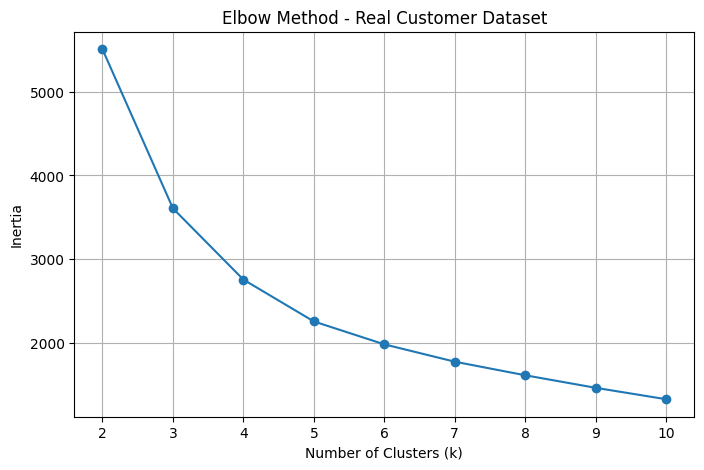

Inertia values: [5506.785466577299, 3606.546896173635, 2755.6361892827786, 2255.9492143651314, 1982.363836624923, 1775.2003100906622, 1613.0557057717685, 1463.2086002241374, 1326.883702321681]


In [228]:
inertia_values = []
k_values = range(2, 11)

for k in k_values:
    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    kmeans.fit(X_scaled)
    inertia_values.append(kmeans.inertia_)

plt.figure(figsize=(8, 5))
plt.plot(k_values, inertia_values, marker="o")

plt.xlabel("Number of Clusters (k)")
plt.ylabel("Inertia")
plt.title("Elbow Method - Real Customer Dataset")
plt.xticks(list(k_values))
plt.grid(True)
plt.show()

print("Inertia values:", inertia_values)

In [229]:
# Train K-Means with 4 clusters
kmeans = KMeans(
    n_clusters=4,
    random_state=42,
    n_init=10
)

customer_data["Cluster"] = kmeans.fit_predict(X_scaled)

print("Model trained successfully!")
print("\nCluster assignments:")
print(customer_data["Cluster"].value_counts().sort_index())

Model trained successfully!

Cluster assignments:
Cluster
0    1597
1     368
2    1171
3    1202
Name: count, dtype: int64


In [230]:
score = silhouette_score(X_scaled, customer_data["Cluster"])

print("Silhouette Score:", round(score, 4))

Silhouette Score: 0.372


In [231]:
cluster_summary = customer_data.groupby("Cluster").agg(
    Customer_Count=("CustomerID", "count"),
    Avg_Spending=("Total_Spending", "mean"),
    Avg_Orders=("Total_Orders", "mean"),
    Avg_Quantity=("Total_Quantity", "mean"),
    Median_Spending=("Total_Spending", "median"),
    Median_Orders=("Total_Orders", "median")
).round(2)

display(cluster_summary)

,Customer_Count,Avg_Spending,Avg_Orders,Avg_Quantity,Median_Spending,Median_Orders
Cluster,,,,,,
0,1597,657.57,2.15,393.04,599.68,2.0
1,368,13681.94,19.63,7825.05,6356.54,15.0
2,1171,2181.09,5.49,1298.74,1856.63,5.0
3,1202,206.37,1.21,103.05,189.48,1.0


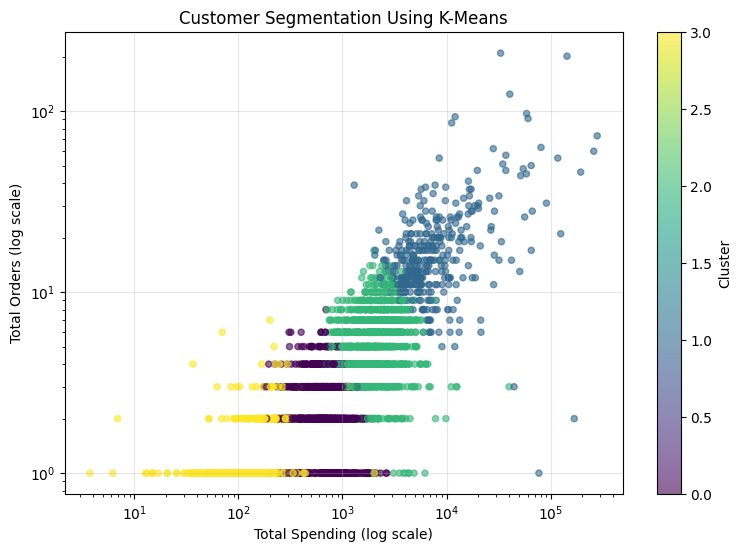

In [232]:
plt.figure(figsize=(9, 6))

plt.scatter(
    customer_data["Total_Spending"],
    customer_data["Total_Orders"],
    c=customer_data["Cluster"],
    cmap="viridis",
    s=20,
    alpha=0.6
)

plt.xscale("log")
plt.yscale("log")

plt.xlabel("Total Spending (log scale)")
plt.ylabel("Total Orders (log scale)")
plt.title("Customer Segmentation Using K-Means")
plt.colorbar(label="Cluster")
plt.grid(True, alpha=0.3)
plt.show()

In [233]:
from sklearn.metrics import silhouette_score

silhouette_results = {}

for k in range(2, 9):
    model = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    cluster_labels = model.fit_predict(X_scaled)

    score = silhouette_score(
        X_scaled,
        cluster_labels
    )

    silhouette_results[k] = score

for k, score in silhouette_results.items():
    print(f"k = {k}: Silhouette Score = {score:.4f}")

k = 2: Silhouette Score = 0.4987
k = 3: Silhouette Score = 0.4160
k = 4: Silhouette Score = 0.3720
k = 5: Silhouette Score = 0.3484
k = 6: Silhouette Score = 0.3232
k = 7: Silhouette Score = 0.3164
k = 8: Silhouette Score = 0.3117


In [234]:
# Train the selected K-Means model
final_kmeans = KMeans(
    n_clusters=2,
    random_state=42,
    n_init=10
)

customer_data["Final_Cluster"] = final_kmeans.fit_predict(
    X_scaled
)

print("Final model trained successfully!")

print("\nCustomer distribution:")
print(
    customer_data["Final_Cluster"]
    .value_counts()
    .sort_index()
)

print(
    "\nFinal Silhouette Score:",
    round(
        silhouette_score(
            X_scaled,
            customer_data["Final_Cluster"]
        ),
        4
    )
)

Final model trained successfully!

Customer distribution:
Final_Cluster
0    1677
1    2661
Name: count, dtype: int64

Final Silhouette Score: 0.4987


In [235]:
final_summary = customer_data.groupby("Final_Cluster").agg(
    Customer_Count=("CustomerID", "count"),
    Avg_Spending=("Total_Spending", "mean"),
    Median_Spending=("Total_Spending", "median"),
    Avg_Orders=("Total_Orders", "mean"),
    Median_Orders=("Total_Orders", "median"),
    Avg_Quantity=("Total_Quantity", "mean"),
    Median_Quantity=("Total_Quantity", "median")
).round(2)

display(final_summary)

,Customer_Count,Avg_Spending,Median_Spending,Avg_Orders,Median_Orders,Avg_Quantity,Median_Quantity
Final_Cluster,,,,,,,
0,1677,4616.60,2100.60,8.39,6.0,2681.42,1260.0
1,2661,430.35,356.98,1.68,1.0,246.25,197.0


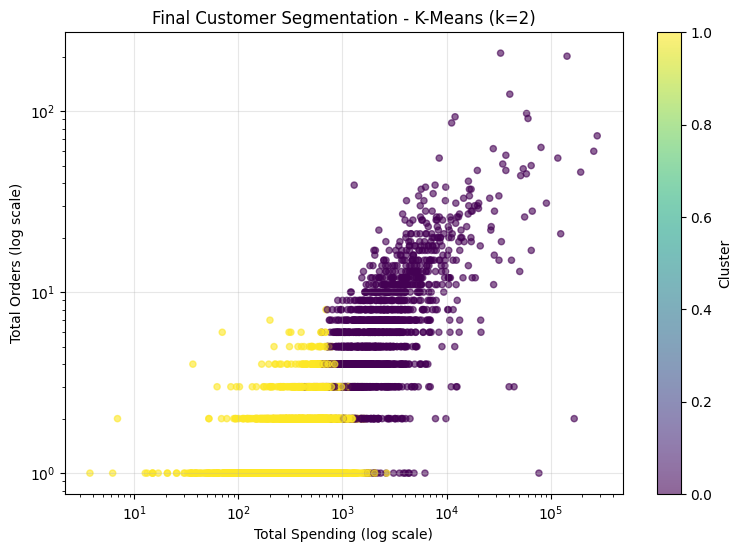

In [236]:
plt.figure(figsize=(9, 6))

plt.scatter(
    customer_data["Total_Spending"],
    customer_data["Total_Orders"],
    c=customer_data["Final_Cluster"],
    cmap="viridis",
    s=20,
    alpha=0.6
)

plt.xscale("log")
plt.yscale("log")

plt.xlabel("Total Spending (log scale)")
plt.ylabel("Total Orders (log scale)")
plt.title("Final Customer Segmentation - K-Means (k=2)")
plt.colorbar(label="Cluster")
plt.grid(True, alpha=0.3)
plt.show()

In [237]:
customer_data.to_csv(
    "customer_segmentation_results.csv",
    index=False
)

print("Results saved successfully!")

Results saved successfully!
